In [195]:
import pandas as pd
import matplotlib.pyplot as plt
import numpy as np
import plotly.express as px
import seaborn as sns
import folium as fs
import numpy as np

In [2]:
df=pd.read_csv("Dataset .csv")

In [136]:
df

,Restaurant ID,Restaurant Name,Country Code,City,Address,Locality,Locality Verbose,Longitude,Latitude,Cuisines,...,Has Table booking,Has Online delivery,Is delivering now,Switch to order menu,Price range,Aggregate rating,Rating color,Rating text,Votes,Cluster
0,6317637,Le Petit Souffle,162,Makati City,"Third Floor, Century City Mall, Kalayaan Avenu...","Century City Mall, Poblacion, Makati City","Century City Mall, Poblacion, Makati City, Mak...",121.027535,14.565443,"French, Japanese, Desserts",...,Yes,No,No,No,3,4.8,Dark Green,5,314,0
1,6304287,Izakaya Kikufuji,162,Makati City,"Little Tokyo, 2277 Chino Roces Avenue, Legaspi...","Little Tokyo, Legaspi Village, Makati City","Little Tokyo, Legaspi Village, Makati City, Ma...",121.014101,14.553708,Japanese,...,Yes,No,No,No,3,4.5,Dark Green,5,591,0
2,6300002,Heat - Edsa Shangri-La,162,Mandaluyong City,"Edsa Shangri-La, 1 Garden Way, Ortigas, Mandal...","Edsa Shangri-La, Ortigas, Mandaluyong City","Edsa Shangri-La, Ortigas, Mandaluyong City, Ma...",121.056831,14.581404,"Seafood, Asian, Filipino, Indian",...,Yes,No,No,No,4,4.4,Green,4,270,0
3,6318506,Ooma,162,Mandaluyong City,"Third Floor, Mega Fashion Hall, SM Megamall, O...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.056475,14.585318,"Japanese, Sushi",...,No,No,No,No,4,4.9,Dark Green,5,365,0
4,6314302,Sambo Kojin,162,Mandaluyong City,"Third Floor, Mega Atrium, SM Megamall, Ortigas...","SM Megamall, Ortigas, Mandaluyong City","SM Megamall, Ortigas, Mandaluyong City, Mandal...",121.057508,14.584450,"Japanese, Korean",...,Yes,No,No,No,4,4.8,Dark Green,5,229,0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
9546,5915730,Naml۱ Gurme,208,stanbul,"Kemanke Karamustafa Paa Mahallesi, R۱ht۱m Cadd...",Karak_y,"Karak_y, stanbul",28.977392,41.022793,Turkish,...,No,No,No,No,3,4.1,Green,4,788,4
9547,5908749,Ceviz Aac۱,208,stanbul,"Kouyolu Mahallesi, Muhittin st_nda Caddesi, No...",Kouyolu,"Kouyolu, stanbul",29.041297,41.009847,"World Cuisine, Patisserie, Cafe",...,No,No,No,No,3,4.2,Green,4,1034,4
9548,5915807,Huqqa,208,stanbul,"Kuru_eme Mahallesi, Muallim Naci Caddesi, No 5...",Kuru_eme,"Kuru_eme, stanbul",29.034640,41.055817,"Italian, World Cuisine",...,No,No,No,No,4,3.7,Yellow,3,661,4
9549,5916112,Ak Kahve,208,stanbul,"Kuru_eme Mahallesi, Muallim Naci Caddesi, No 6...",Kuru_eme,"Kuru_eme, stanbul",29.036019,41.057979,Restaurant Cafe,...,No,No,No,No,4,4.0,Green,4,901,4


In [23]:
df.isnull().sum()

Restaurant ID           0
Restaurant Name         0
Country Code            0
City                    0
Address                 0
Locality                0
Locality Verbose        0
Longitude               0
Latitude                0
Cuisines                0
Average Cost for two    0
Currency                0
Has Table booking       0
Has Online delivery     0
Is delivering now       0
Switch to order menu    0
Price range             0
Aggregate rating        0
Rating color            0
Rating text             0
Votes                   0
dtype: int64

In [5]:
df['Restaurant Name'] = df['Restaurant Name'].str.replace("�","",regex=False)

In [6]:
df['City'] = df['City'].str.replace("�","",regex=False)

In [7]:
df['Address'] = df['Address'].str.replace("�","",regex=False)

In [8]:
df['Locality'] = df['Locality'].str.replace("�","",regex=False)

In [9]:
df['Locality Verbose'] = df['Locality Verbose'].str.replace("�","",regex=False)

In [10]:
df.dropna(inplace=True)

LEVEL 2 TASK 1

Text(0, 0.5, 'frequency')

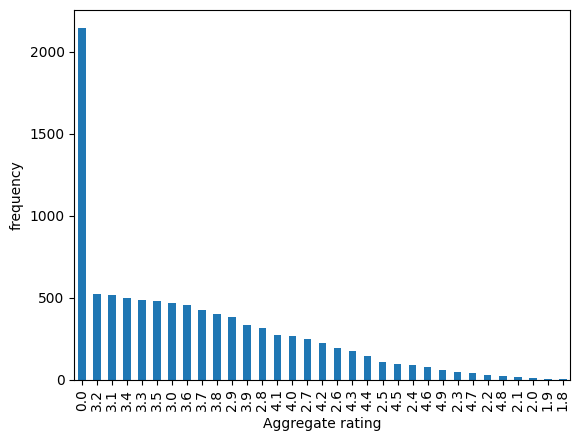

In [39]:
df['Aggregate rating'].value_counts().plot(kind='bar')
plt.ylabel('frequency')

In [31]:
df['Aggregate rating'].value_counts().head(1)

Aggregate rating
0.0    2148
Name: count, dtype: int64

In [40]:
rating_bins = pd.cut(df['Aggregate rating'], bins=[0,1,2,3,4,5])
rating_bins.value_counts().head(1)

Aggregate rating
(3, 4]    4381
Name: count, dtype: int64

In [44]:
df['Votes'].mean()

np.float64(156.7720603647034)

TASK 2

In [45]:
df['Cuisines'].value_counts().head(1)

Cuisines
North Indian    936
Name: count, dtype: int64

In [68]:
df.groupby('Cuisines')['Aggregate rating'].mean().sort_values(ascending=0).head(18)

Cuisines
Burger, Bar Food, Steak            4.9
American, Burger, Grill            4.9
American, Caribbean, Seafood       4.9
American, Coffee and Tea           4.9
Mexican, American, Healthy Food    4.9
Italian, Bakery, Continental       4.9
BBQ, Breakfast, Southern           4.9
European, German                   4.9
Hawaiian, Seafood                  4.9
Sunda, Indonesian                  4.9
American, BBQ, Sandwich            4.9
World Cuisine                      4.9
Continental, Indian                4.9
American, Sandwich, Tea            4.9
Mughlai, Lucknowi                  4.9
European, Contemporary             4.9
European, Asian, Indian            4.9
Italian, Deli                      4.9
Name: Aggregate rating, dtype: float64

TASK 3

In [73]:
geo_df = df.dropna(subset=['Latitude', 'Longitude'])
map_center = [geo_df['Latitude'].mean(), geo_df['Longitude'].mean()]
restaurant_map = fs.Map(location=map_center, zoom_start=12)
for i, row in geo_df.head(500).iterrows():
    fs.CircleMarker(
        location=[row['Latitude'], row['Longitude']],
        radius=3
    ).add_to(restaurant_map)
restaurant_map

In [90]:
restaurant_map.save("Restaurant_Map.html")

In [98]:
d=df['Restaurant Name'].value_counts()

In [99]:
d

Restaurant Name
Cafe Coffee Day     83
Domino's Pizza      79
Subway              63
Green Chick Chop    51
McDonald's          48
                    ..
ukuraa Sofras۱       1
Gaga Manjero         1
Cafemiz              1
Nusr-Et              1
Maori                1
Name: count, Length: 7437, dtype: int64

In [112]:
f=d[d>1]

In [116]:
kf=df[df['Restaurant Name'].isin(f.index)]

In [119]:
kf.groupby('Restaurant Name')['Aggregate rating'].mean().sort_values(ascending=False)

Restaurant Name
Talaga Sampireun             4.900
Silantro Fil-Mex             4.850
AB's Absolute Barbecues      4.850
AB's - Absolute Barbecues    4.825
Naturals Ice Cream           4.800
                             ...  
Kake Da Dhaba                0.000
Bake Walkers                 0.000
Kettle & Kegs                0.000
Kesarwa Bakez                0.000
Aap Ki Khatir                0.000
Name: Aggregate rating, Length: 734, dtype: float64